# Staffing Boston's 311 city service teams

IE 5374 hackathon. Team: Nishanth Manoharan, Ramgopal Reddy Alumalla, Aryan Patil.

This notebook calls the same functions in `src/boston311/` as the web app, so the analysis and the product can't drift apart. Before running it, build the data:

```
uv run python scripts/download_data.py
uv run python scripts/build_processed.py
```

> **AI use: to be confirmed with the team.** The brief (section 7) asks us to explain how we used AI tools and to mark AI-generated sections. The wording will be agreed by Nishanth, Aryan and Ram before submission.

## 1. Setup

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from boston311.config import DEPARTMENTS, INTERIM_DIR, PROCESSED_DIR
from boston311.data.aggregate import RESIDENT_SOURCES, query_service_stats

pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update(
    {"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False}
)
NAMES = {code: d["name"] for code, d in DEPARTMENTS.items()}

monthly = pd.read_csv(PROCESSED_DIR / "monthly_demand.csv")
daily = pd.read_csv(PROCESSED_DIR / "daily_profile.csv", parse_dates=["date"])
sla = pd.read_csv(PROCESSED_DIR / "sla_profile.csv")
types = pd.read_csv(PROCESSED_DIR / "request_types.csv")
stats = pd.read_parquet(PROCESSED_DIR / "service_stats.parquet")

## 2. Exploring the 311 data

The pipeline keeps the four departments in scope (by the `department` column) from the 2023, 2024 and January to September 2025 files. 2025 is only used to check the forecast.

### 2.1 The 2024 counts reproduce the brief

In [2]:
monthly["year"] = monthly["month"].str[:4]
by_year = monthly.pivot_table(
    index="department", columns="year", values="requests", aggfunc="sum"
).reindex(list(DEPARTMENTS))
by_year["brief 2024"] = [d["requests_2024"] for d in DEPARTMENTS.values()]
by_year["2024 matches"] = by_year["2024"] == by_year["brief 2024"]
by_year.rename(columns={"2025": "2025 (Jan-Sep)"})

year,2023,2024,2025 (Jan-Sep),brief 2024,2024 matches
department,,,,,
PWDx,171268,157610,105437,157610,True
BTDT,75314,81447,61696,81447,True
PARK,17541,18736,12075,18736,True
ISD,18123,18624,13874,18624,True


### 2.2 Monthly demand is seasonal, and each department peaks differently

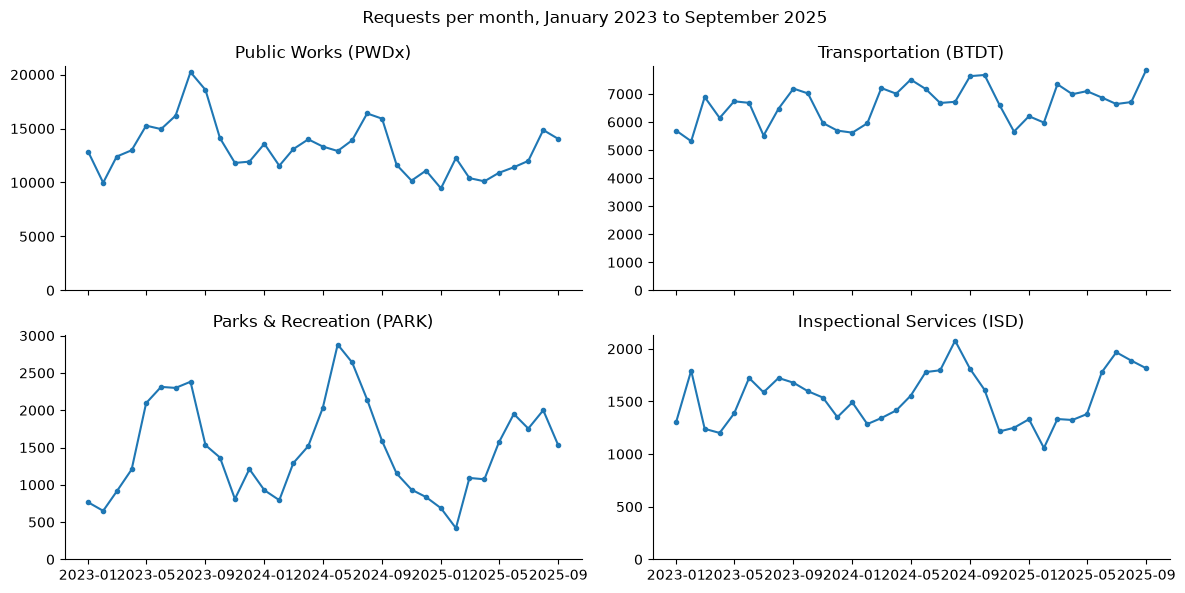

In [3]:
monthly["date"] = pd.to_datetime(monthly["month"])
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for ax, code in zip(axes.flat, DEPARTMENTS, strict=True):
    d = monthly[monthly["department"] == code]
    ax.plot(d["date"], d["requests"], marker=".")
    ax.set_title(f"{NAMES[code]} ({code})")
    ax.set_ylim(bottom=0)
fig.suptitle("Requests per month, January 2023 to September 2025")
fig.tight_layout()

In [4]:
# each month's 2024 requests divided by that department's 2024 monthly average
m24 = monthly[monthly["year"] == "2024"].copy()
m24["month_num"] = m24["month"].str[5:].astype(int)
season = m24.pivot(index="department", columns="month_num", values="requests")
season = season.div(season.mean(axis=1), axis=0).reindex(list(DEPARTMENTS))
season["peak / trough"] = season.max(axis=1) / season.min(axis=1)
season.round(2)

month_num,1,2,3,4,5,6,7,8,9,10,11,12,peak / trough
department,,,,,,,,,,,,,
PWDx,1.030,0.880,1.000,1.070,1.020,0.980,1.060,1.250,1.210,0.890,0.770,0.850,1.610
BTDT,0.830,0.880,1.060,1.030,1.110,1.060,0.980,0.990,1.120,1.130,0.970,0.830,1.370
PARK,0.590,0.510,0.830,0.970,1.300,1.850,1.690,1.370,1.020,0.740,0.600,0.540,3.630
ISD,0.960,0.830,0.860,0.910,1.000,1.150,1.160,1.340,1.170,1.040,0.780,0.810,1.710


### 2.3 Requests arrive every day, but far fewer on weekends

In [5]:
daily["weekday"] = daily["date"].dt.day_name().str[:3]
order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday = daily.pivot_table(
    index="department", columns="weekday", values="requests", aggfunc="mean"
)[order].reindex(list(DEPARTMENTS))
weekday.round(0)

weekday,Mon,Tue,Wed,Thu,Fri,Sat,Sun
department,,,,,,,
PWDx,538.000,561.000,535.000,482.000,453.000,305.000,275.000
BTDT,232.000,249.000,252.000,247.000,234.000,153.000,134.000
PARK,61.000,60.000,61.000,60.000,52.000,27.000,26.000
ISD,63.000,64.000,60.000,58.000,54.000,29.000,24.000


### 2.4 On-time rates

Requests with no target date count as workload but are left out of the on-time rate (working assumption 3). The brief's figures count them as on time, so Public Works and Transportation come out lower here. These are the numbers the simulator's 2024 baseline is compared with.

In [6]:
s24 = stats[stats["year"] == 2024]
on_time = pd.DataFrame(query_service_stats("on_time_rate", "department", {"year": 2024}))
on_time = on_time.set_index("department").reindex(list(DEPARTMENTS))
on_time["brief"] = [d["on_time_2024"] for d in DEPARTMENTS.values()]
on_time["no target date"] = s24["on_time"].isna().groupby(s24["department"]).mean()
on_time

,on_time_rate,brief,no target date
department,,,
PWDx,0.873,0.900,0.186
BTDT,0.489,0.500,0.020
PARK,0.930,0.930,0.022
ISD,0.723,0.720,0.004


### 2.5 Target windows

The simulator splits each day's requests across target windows in these 2024 shares. Parks has many 365-day targets, so its on-time rate says little about how fast it works.

In [7]:
bins = [-1, 1, 3, 7, 14, 30, 90, 364, 10_000]
labels = ["<=1", "2-3", "4-7", "8-14", "15-30", "31-90", "91-364", "365+"]
sla["window"] = pd.cut(sla["target_days"], bins, labels=labels)
sla["window"] = sla["window"].cat.add_categories("none").fillna("none")
windows = sla.pivot_table(
    index="department", columns="window", values="share", aggfunc="sum", observed=False
).reindex(list(DEPARTMENTS))
(windows * 100).round(1)

window,<=1,2-3,4-7,8-14,15-30,31-90,91-364,365+,none
department,,,,,,,,,
PWDx,26.600,29.400,17.500,2.300,4.600,0.600,0.100,0.200,18.600
BTDT,42.300,33.000,7.400,2.700,11.300,0.900,0.200,0.100,2.000
PARK,4.100,4.500,15.600,16.000,0.500,0.100,0.100,57.000,2.200
ISD,3.300,10.200,10.600,3.400,30.000,8.300,25.500,8.300,0.400


### 2.6 Who logs requests

City staff (Employee Generated and the City Worker App) log more than half of the requests in these four departments, more than the brief's 42% across all departments. Section 8 compares their on-time rates and close times with residents' requests.

In [8]:
source = s24.pivot_table(
    index="department", columns="source", values="year", aggfunc="size", fill_value=0
).reindex(list(DEPARTMENTS))
share = source.div(source.sum(axis=1), axis=0)
share["resident total"] = share[sorted(RESIDENT_SOURCES)].sum(axis=1)
share["staff total"] = 1 - share["resident total"]
(share * 100).round(1)

source,Citizens Connect App,City Worker App,Constituent Call,Employee Generated,Self Service,resident total,staff total
department,,,,,,,
PWDx,21.600,16.100,22.500,33.500,6.200,50.400,49.600
BTDT,32.900,0.300,4.900,61.300,0.600,38.400,61.600
PARK,27.400,23.800,11.100,36.500,1.200,39.700,60.300
ISD,13.300,1.300,42.700,39.000,3.800,59.700,40.300


### 2.7 Request types

158 request types appear in the four departments in 2024. A few types make up most of each department's work. The intake assistant routes to these types, and each type's department and queue come from this table.

In [9]:
print(types.groupby("department")["request_type"].count().reindex(list(DEPARTMENTS)))
top5 = types.groupby("department").head(5)  # types is sorted by requests
top5 = top5.assign(order=top5["department"].map(list(DEPARTMENTS).index))
top5.sort_values(["order", "requests"], ascending=[True, False]).set_index(
    ["department", "request_type"]
)[["requests", "median_days_to_close", "queue"]]

department
PWDx    62
BTDT    22
PARK    12
ISD     62
Name: request_type, dtype: int64


requests  \
department request_type                                            
PWDx       Requests for Street Cleaning                    20564   
           Improper Storage of Trash (Barrels)             20340   
           CE Collection                                   18011   
           Schedule a Bulk Item Pickup                     11828   
           Missed Trash/Recycling/Yard Waste/Bulk Item     10588   
BTDT       Parking Enforcement                             63064   
           Sign Repair                                      4876   
           Abandoned Vehicles                               4759   
           Traffic Signal Inspection                        3773   
           New Sign  Crosswalk or Pavement Marking           945   
PARK       Tree Maintenance Requests                        8355   
           Ground Maintenance                               3183   
           New Tree Requests                                2577   
           Equipment Repair                                 2441   
           Tree Emergencies                                  727   
ISD        Rodent Activity                                  4936   
           Unsatisfactory Living Conditions                 2383   
           Pest Infestation - Residential                   1952   
           Contractors Complaint                             923   
           Work w/out Permit                                 896   

                                                        median_days_to_close  \
department request_type                                                        
PWDx       Requests for Street Cleaning                                0.100   
           Improper Storage of Trash (Barrels)                         0.100   
           CE Collection                                               0.100   
           Schedule a Bulk Item Pickup                                 0.700   
           Missed Trash/Recycling/Yard Waste/Bulk Item                 0.500   
BTDT       Parking Enforcement                                         0.800   
           Sign Repair                                                 6.300   
           Abandoned Vehicles                                         44.100   
           Traffic Signal Inspection                                   0.500   
           New Sign  Crosswalk or Pavement Marking                    21.100   
PARK       Tree Maintenance Requests                                   9.100   
           Ground Maintenance                                          0.800   
           New Tree Requests                                          47.600   
           Equipment Repair                                            2.300   
           Tree Emergencies                                            0.100   
ISD        Rodent Activity                                             1.000   
           Unsatisfactory Living Conditions                           11.000   
           Pest Infestation - Residential                              3.400   
           Contractors Complaint                                       9.800   
           Work w/out Permit                                          10.600   

                                                                                                    queue  
department request_type                                                                                    
PWDx       Requests for Street Cleaning                                        PWDx_District 1C: Downtown  
           Improper Storage of Trash (Barrels)                                      PWDx_Code Enforcement  
           CE Collection                                                       PWDx_District 1C: Downtown  
           Schedule a Bulk Item Pickup                                   PWDx_Schedule a Bulk Item Pickup  
           Missed Trash/Recycling/Yard Waste/Bulk Item   PWDx_Missed Trash\Recycling\Yard Waste\Bulk Item  
BTDT       Parking Enforcement            

In [10]:
# share of each department's 2024 requests covered by its top 5 and top 10 types
ranked = types.sort_values("requests", ascending=False).groupby("department")
total = types.groupby("department")["requests"].sum()
pd.DataFrame(
    {
        "types": ranked.size(),
        "top 5 share": ranked.head(5).groupby("department")["requests"].sum() / total,
        "top 10 share": ranked.head(10).groupby("department")["requests"].sum() / total,
    }
).reindex(list(DEPARTMENTS))

,types,top 5 share,top 10 share
department,,,
PWDx,62,0.513,0.766
BTDT,22,0.951,0.993
PARK,12,0.972,0.999
ISD,62,0.597,0.764


### 2.8 `case_title` is messy

Titles are free text with internal codes and HTML entities. The pipeline unescapes the entities, but the intake assistant routes to `type`, not to titles.

In [11]:
raw24 = pd.read_parquet(
    INTERIM_DIR / "clean_2024.parquet", columns=["department", "case_title", "request_type"]
)
print(
    f"{raw24['case_title'].nunique():,} distinct titles across "
    f"{raw24['request_type'].nunique()} request types in 2024"
)
raw24.groupby("request_type")["case_title"].nunique().sort_values(ascending=False).head(8)

3,422 distinct titles across 158 request types in 2024


request_type
Unsatisfactory Living Conditions       640
Street Light Outages                   333
Maintenance Complaint - Residential    283
Equipment Repair                       234
Ground Maintenance                     221
Heat - Excessive  Insufficient         214
Pest Infestation - Residential         184
Chronic Dampness/Mold                  156
Name: case_title, dtype: int64

### 2.9 What this means for the plan

- **Parks is the most seasonal department.** Its June demand is 3.6 times its February demand, which is what the April to October seasonal crews are for. Public Works peaks in August and September, and Public Works and Transportation swing much less, so hires and releases there have to pay for their training month and release fee.
- **Crews work weekdays, but requests arrive every day.** Weekend days bring about half of a weekday's requests, and the simulator queues them for Monday.
- **Transportation has the lowest on-time rate, 49%, on the tightest targets.** Parking enforcement is about three quarters of its requests, and 42% of its requests have a target of one day or less.
- **Target windows differ a lot by department.** 57% of Parks requests have targets of a year or more, so a high Parks on-time rate is easy to reach. Public Works has the most requests with no target date (19%), which count as workload but not in on-time %.
- **City staff log 53% of the workload**, and 62% in Transportation. Section 8 compares their requests with residents' requests.

## 3. Demand forecast for 2025

Three methods per department:

- **Seasonal naive:** each month repeats the same month a year earlier.
- **Naive × year-over-year growth:** seasonal naive, scaled by the last months' growth over the same months a year earlier.
- **Damped ETS:** a damped-trend exponential smoothing model on demand with the monthly pattern divided out, then put back. The pattern comes from the latest full year, because a seasonal ETS needs 24 months and the backtest trains on 18.

The backtest trains on January 2023 to June 2024 and predicts July to December 2024. Each department uses its lowest-MAPE method, refit on all of 2023 and 2024. The 80% interval is the forecast × (1 ± 1.28 × the method's RMS percentage error in the backtest). The January to September 2025 actuals are only a check: they never pick a method or enter a fit.

### 3.1 Backtest: mean absolute percentage error, July to December 2024

In [12]:
from boston311.forecast import backtest as bt
from boston311.forecast.models import load_forecast

series = bt.monthly_series()
results = bt.backtest(series)
chosen = bt.choose(results).set_index("department").loc[list(DEPARTMENTS)]
mape = results.pivot(index="department", columns="method", values="mape")
mape = mape.loc[list(DEPARTMENTS), ["seasonal_naive", "naive_yoy", "damped_ets"]]
mape["chosen"] = chosen["method"]
mape["chosen RMS % error"] = chosen["rmspe"]
mape

method,seasonal_naive,naive_yoy,damped_ets,chosen,chosen RMS % error
department,,,,,
PWDx,0.169,0.170,0.038,damped_ets,0.053
BTDT,0.076,0.048,0.064,naive_yoy,0.060
PARK,0.174,0.278,0.352,seasonal_naive,0.217
ISD,0.119,0.119,0.129,seasonal_naive,0.144


### 3.2 The 2025 forecast with its 80% interval, and the 2025 actuals so far

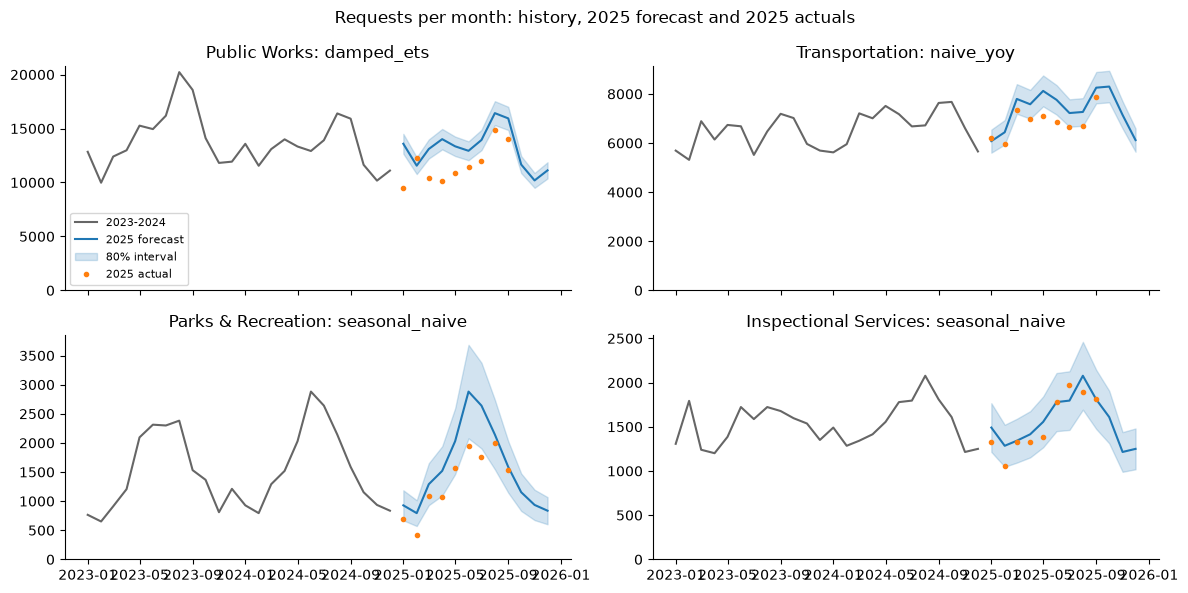

In [13]:
forecast = pd.read_parquet(PROCESSED_DIR / "forecast_2025.parquet")
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for ax, code in zip(axes.flat, DEPARTMENTS, strict=True):
    hist = series[code]
    f = forecast[forecast["department"] == code]
    x = pd.to_datetime(f["month"])
    ax.plot(
        pd.to_datetime(hist.loc[:"2024-12"].index),
        hist.loc[:"2024-12"],
        color="0.4",
        label="2023-2024",
    )
    ax.plot(x, f["forecast"], color="C0", label="2025 forecast")
    ax.fill_between(x, f["lower"], f["upper"], color="C0", alpha=0.2, label="80% interval")
    actual = hist.loc["2025-01":]
    ax.plot(pd.to_datetime(actual.index), actual, "o", color="C1", ms=3, label="2025 actual")
    ax.set_title(f"{NAMES[code]}: {chosen.loc[code, 'method']}")
    ax.set_ylim(bottom=0)
axes[0, 0].legend(fontsize=8)
fig.suptitle("Requests per month: history, 2025 forecast and 2025 actuals")
fig.tight_layout()

### 3.3 Check against January to September 2025

Bias is the mean of (forecast − actual) / actual, so a positive bias means the forecast was too high. `inside_80` is the share of months whose actual fell inside the 80% interval. `actual_vs_forecast` is total actual requests over total forecast for the nine months.

In [14]:
bt.check_2025(series, forecast).set_index("department")

,months,mape,bias,inside_80,actual_vs_forecast
department,,,,,
PWDx,9,0.211,0.199,0.111,0.844
BTDT,9,0.082,0.077,0.556,0.928
PARK,9,0.359,0.359,0.556,0.764
ISD,9,0.081,0.061,1.000,0.954


### 3.4 Why 2025 came in lower

The same nine months of 2024 and 2025, by how the request came in.

In [15]:
def by_source(year):
    df = pd.read_parquet(
        INTERIM_DIR / f"clean_{year}.parquet", columns=["department", "source", "month"]
    )
    df = df[df["month"].str[5:] <= "09"]  # January to September
    return df.groupby(["department", "source"]).size()


# 2025 has a source 2024 doesn't (Maximo Integration), so fill the gap with 0
change = pd.DataFrame({"Jan-Sep 2024": by_source(2024), "Jan-Sep 2025": by_source(2025)})
change = change.fillna(0).astype(int)
change["2025 / 2024"] = change["Jan-Sep 2025"] / change["Jan-Sep 2024"]
change.loc[list(DEPARTMENTS)].round(2)

Jan-Sep 2024  Jan-Sep 2025  2025 / 2024
department source                                                       
PWDx       Citizens Connect App         26921         28194        1.050
           City Worker App              20234         19127        0.950
           Constituent Call             29760         13911        0.470
           Employee Generated           40131         42448        1.060
           Self Service                  7651          1757        0.230
BTDT       Citizens Connect App         20279         20344        1.000
           City Worker App                188           144        0.770
           Constituent Call              3119          3115        1.000
           Employee Generated           37547         37757        1.010
           Self Service                   375           336        0.900
PARK       Citizens Connect App          4254          4256        1.000
           City Worker App               3921          2105        0.540
           Constituent Call              1724          1513        0.880
           Employee Generated            5726          4019        0.700
           Self Service                   187           182        0.970
ISD        Citizens Connect App          1953          1857        0.950
           City Worker App                178           417        2.340
           Constituent Call              6125          5881        0.960
           Employee Generated            5798          5126        0.880
           Maximo Integration               0             2          inf
           Self Service                   495           591        1.190

### 3.5 The 2025 forecast the staffing plan uses

In [16]:
table = pd.DataFrame(
    {d.department: [m.forecast for m in d.months] for d in load_forecast().departments},
    index=[f"2025-{m:02d}" for m in range(1, 13)],
)
table.loc["total"] = table.sum()
table.round(0).astype(int)

,PWDx,BTDT,PARK,ISD
2025-01,13588,6078,928,1491
2025-02,11558,6439,794,1285
2025-03,13105,7796,1291,1342
2025-04,14014,7579,1519,1415
2025-05,13351,8123,2029,1555
2025-06,12936,7760,2881,1779
2025-07,13937,7222,2640,1796
2025-08,16425,7266,2143,2077
2025-09,15940,8255,1587,1809
2025-10,11660,8300,1153,1610


### 3.6 What the forecast says

- **Each department gets a different method.** Public Works uses damped ETS (3.8% backtest MAPE), Transportation naive × growth (4.8%), and Parks and Inspectional Services seasonal naive (17.4% and 11.9%). Parks is the hardest to forecast.
- **2025 looks like 2024.** The forecast totals are 157,828 for Public Works, 88,079 for Transportation (8% above 2024), and 18,736 and 18,624 for Parks and Inspectional Services (their 2024 totals, since seasonal naive repeats 2024).
- **The 2025 check splits the departments.** Transportation and Inspectional Services came within about 8% (MAPE). Public Works and Parks came in well under: their January-September actuals were 84% and 76% of the forecast. Only 1 of 9 Public Works months fell inside its 80% interval, so its interval, built on a 6-month backtest, is too narrow.
- **The 2025 drop is in how requests arrived.** Public Works phone requests fell to 47% of their January-September 2024 level and self-service requests to 23%, while app and employee requests held steady or grew. Parks' City Worker App requests fell to 54% and its employee requests to 70%. These changes came after the 2023-2024 data the forecast is fitted on, and the data alone doesn't say whether the work itself fell.
- **For the plan:** the base case uses this forecast, as the brief asks. Public Works' 2025 so far (16% below forecast) falls between the base case and Section 7's 20%-lower scenario; Parks (24% below) fell further than that scenario.
- **The 80% interval is too narrow.** Its width comes from the same six backtest months that picked each method, and in 2025 it held only 1 of 9 months for Public Works and 5 of 9 for Transportation and Parks (section 3.3). Section 7 tests the plan with scenarios rather than relying on the interval.
- **The forecast ran high.** Every department came in under it in 2025, at 76% to 95% of the forecast, so the plan errs toward too many crews rather than too few. Transportation's method carries 2024's growth of about 8% into all of 2025 from a single pair of years.

## 4. The AI assistants

Two agents built with LangChain `create_agent` on Groq's `openai/gpt-oss` models, each with read-only tools, and each measured against a simpler baseline.

- **Intake assistant:** splits a resident's message into problems, searches the 158 request types (local embeddings over an LLM-written knowledge base), checks the candidates, and returns the request type. Department, queue and typical days to close always come from the lookup table built in section 2, never from the model. Baseline: one retrieval plus one structured-output call.
- **Planning analyst:** answers questions about the plan, the forecast and the 311 history with four tools (`get_plan`, `run_what_if`, `get_forecast`, `query_service_stats`), and the server flags any number in its answer that no tool returned.

### 4.1 Intake: held-out test set

45 messages written by a teammate who didn't build the agent (25 clear, 8 ambiguous, 6 with several problems, 6 out of scope or messy), run once on `gpt-oss-120b`. A problem counts as right if the predicted type is one of its accepted types.

In [17]:
from boston311.config import ROOT


def report_summary(path):
    """The first table in an eval report: its summary row(s)."""
    lines = [line for line in (ROOT / path).read_text().splitlines() if line.startswith("|")]
    header = [h.strip() for h in lines[0].strip("|").split("|")]
    rows = []
    for line in lines[2:]:
        cells = [c.strip() for c in line.strip("|").split("|")]
        if len(cells) != len(header):
            break  # the next table starts
        rows.append(cells)
    return pd.DataFrame(rows, columns=header).set_index(header[0])


report_summary("reports/eval/intake_test.md").T

path,pipeline,agent
messages,45,45
errors,0,0
type correct,31/41,33/41
department correct,34/41,37/41
queue correct,33/41,35/41
split correct,4/6,6/6
follow-up precision,2/2,0/0
follow-up recall,2/8,0/8
out of scope correct,2/3,3/3
tool calls / msg,0.0,1.4


### What the intake results say

- **The agent routes better than the single-call pipeline:** request type 33/41 against 31/41, department 37/41 against 34/41, queue 35/41 against 33/41. It also split all 6 messages with several problems (pipeline 4/6) and caught all 3 out-of-scope messages (pipeline 2/3).
- **It never asks a follow-up question.** On the 8 ambiguous messages it filed its best guess every time (0/8); the pipeline asked on 2 of them. This is the main gap.
- **It fell back to the pipeline on 12 of 45 messages**, when Groq rejected a malformed tool call or the answer failed validation twice, so some of its answers are the pipeline's.
- **It costs about twice as many tokens:** 1303.9 uncached tokens per message against 614.3, within Groq's free tier.
- This run came before a later fix that treats the text "null" as no follow-up question; it doesn't change the routing scores above.

### 4.2 Planning analyst

The 10-question development set (written while building, so not held out), on `gpt-oss-120b`.

In [18]:
report_summary("reports/eval/analyst_dev.md").T

questions,10
errors,0
right tools,10/10
right arguments,19/19
numbers verified,36/40
tool calls / q,1.1
max tool calls,2
LLM calls / q,2.1
uncached tokens / q,3263.6


- **Right tools on all 10 questions and right arguments on all 19 scored**, using at most 2 tool calls per question (the cap is 6).
- **36 of 40 numbers in the answers were verified** against tool results. The 4 flagged include two numbers the model produced itself: a sum of seasonal crews, and Parks' 18,736 forecast requests written as dollars. That is the check doing its job: the app underlines such numbers.
- _The held-out run (15 questions written by a teammate who didn't build the agent) is added here once that set is in the eval's format._

## 5. Staffing plan for 2025

A small mixed-integer program per department chooses crews, hires, releases and Parks seasonal crews each month at least cost, with capacity at least the forecast plus a buffer. A day-by-day simulation of the year then scores it, and each month's buffer is raised until the department reaches 90% on time. Every number below comes from that simulation. The baseline keeps January's crews all year.

In [19]:
from boston311.planning import sensitivity
from boston311.planning.scenarios import load_plan

base, flat = load_plan("base"), load_plan("hold_flat")
pd.DataFrame(
    {
        name: plan.kpis.model_dump()
        for name, plan in [("2025 plan", base), ("January crews held flat", flat)]
    }
).rename(index=lambda k: k.replace("baseline_", "hold-flat ")).loc[
    ["total_cost", "overdue_cost", "on_time_pct"]
].T.assign(crew_cost=lambda t: t["total_cost"] - t["overdue_cost"]).round(4)

,total_cost,overdue_cost,on_time_pct,crew_cost
2025 plan,"15,909,155.150","399,655.150",0.921,"15,509,500.000"
January crews held flat,"21,047,461.570","9,127,461.570",0.255,"11,920,000.000"


### 5.1 Crews by department and month

Each cell is the crews working that month. `+n` marks crews hired that month (they train for a month, so they start the next one), `-n` crews released (they work out the month), and `s` Parks seasonal crews.

In [20]:
def cell(m):
    text = str(m.active_crews)
    if m.seasonal:
        text += f" +{m.seasonal}s"
    if m.hires:
        text += f" (hire {m.hires})"
    if m.releases:
        text += f" (release {m.releases})"
    return text


months = [m.month for m in base.departments[0].months]
pd.DataFrame(
    {NAMES[d.department]: [cell(m) for m in d.months] for d in base.departments},
    index=[pd.Period(m).strftime("%b") for m in months],
).T

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Public Works,50,50 (hire 3),53 (hire 3),56,56,56,56 (hire 10),66 (release 2),64,64,64,64
Transportation,18 (hire 3),21 (hire 5),26,26,26,26,26,26 (hire 1),27,27,27,27
Parks & Recreation,10,10 (hire 1),11,11 +2s,11 +6s,11 +12s,11 +10s,11 +7s,11 +2s,11,11,11
Inspectional Services,16,16,16 (hire 1),17 (hire 2),19 (hire 3),22,22 (hire 3),25 (release 3),22,22,22,22


### 5.2 By department, for the year

In [21]:
scored = sensitivity.score(sensitivity.staffing(base), dict.fromkeys(DEPARTMENTS, 1.0))
flat_scored = sensitivity.score(sensitivity.staffing(flat), dict.fromkeys(DEPARTMENTS, 1.0))
per_department = pd.DataFrame(
    {
        "hires": {d.department: sum(m.hires for m in d.months) for d in base.departments},
        "releases": {d.department: sum(m.releases for m in d.months) for d in base.departments},
        "seasonal crew-months": {
            d.department: sum(m.seasonal for m in d.months) for d in base.departments
        },
        "January crews": {d.department: d.months[0].active_crews for d in base.departments},
        "December crews": {d.department: d.months[-1].active_crews for d in base.departments},
        "crew cost": scored["crew_cost"],
        "on-time rate": scored["on_time_pct"],
        "on-time, held flat": flat_scored["on_time_pct"],
    }
)
counts = ["hires", "releases", "seasonal crew-months", "January crews", "December crews"]
per_department.loc["all", counts] = per_department.loc[list(DEPARTMENTS), counts].sum()
per_department[counts] = per_department[counts].astype(int)
per_department.loc[list(DEPARTMENTS) + ["all"]].round(3)

,hires,releases,seasonal crew-months,January crews,December crews,crew cost,on-time rate,"on-time, held flat"
PWDx,16,2,0,50,64,"7,810,833.340",0.915,0.271
BTDT,9,0,0,18,27,"2,859,999.980",0.900,0.080
PARK,1,0,39,10,11,"1,817,000.000",0.996,0.634
ISD,9,3,0,16,22,"3,021,666.700",0.978,0.661
all,35,5,39,94,124,"15,509,500.020",0.921,0.255


### 5.3 Capacity against forecast demand

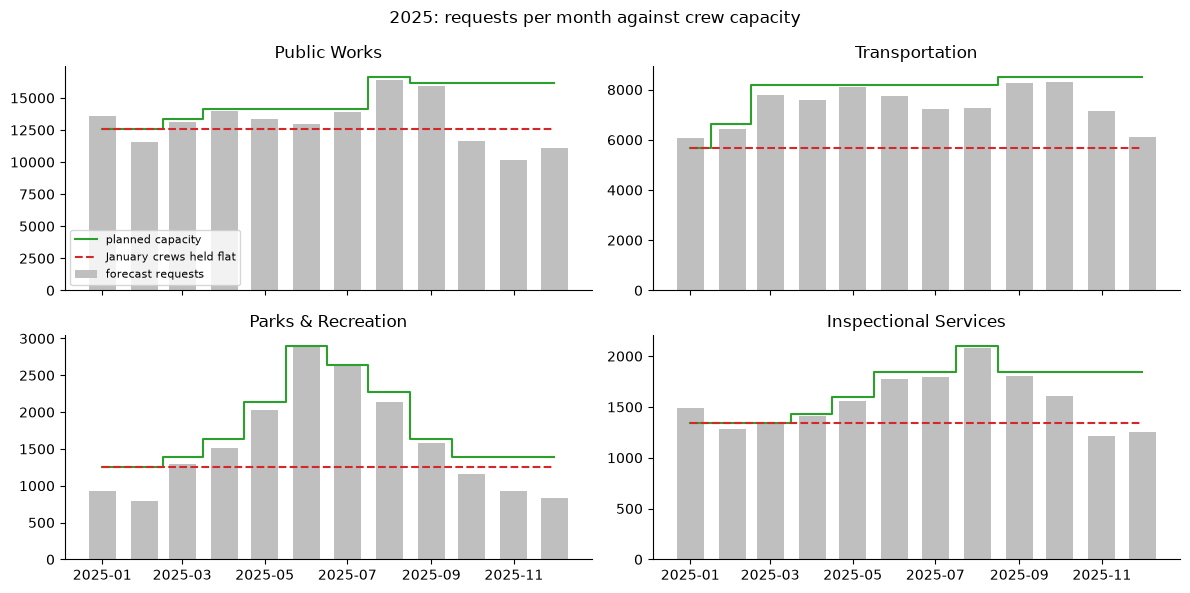

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for ax, d in zip(axes.flat, base.departments, strict=True):
    x = pd.to_datetime([m.month for m in d.months])
    ax.bar(x, [m.forecast for m in d.months], width=20, color="0.75", label="forecast requests")
    ax.step(x, [m.capacity for m in d.months], where="mid", color="C2", label="planned capacity")
    flat_d = next(f for f in flat.departments if f.department == d.department)
    ax.step(
        x,
        [m.capacity for m in flat_d.months],
        where="mid",
        color="C3",
        ls="--",
        label="January crews held flat",
    )
    ax.set_title(NAMES[d.department])
    ax.set_ylim(bottom=0)
axes[0, 0].legend(fontsize=8)
fig.suptitle("2025: requests per month against crew capacity")
fig.tight_layout()

### What the plan does

- **The plan costs $15.91M and closes 92.1% of requests on time, against $21.05M and 25.5% if January crews stay flat.** It spends $15.51M on crews instead of $11.92M, and overdue penalties fall from $9.13M to $0.40M.
- **Every department reaches the 90% target:** Public Works 91.5%, Transportation 90.0%, Parks 99.6% and Inspectional Services 97.8%.
- **Hiring:** Public Works grows from 50 to 64 crews (16 hires, 66 working in August), Transportation from 18 to 27 (9 hires), Inspectional Services from 16 to 22 (9 hires). Parks adds 1 regular crew and 39 seasonal crew-months, up to 12 seasonal crews in June. There are only 5 releases in all, after the August peak.
- **Why holding January crews is so bad:** January's crews are below demand in three departments. With no hiring, the backlog grows all year, and because requests are handled in arrival order, later requests wait behind it and miss their mostly 1- to 3-day targets. Real departments absorb this with overtime and other staff, which the model leaves out, so the 25.5% overstates how bad 2025 would really be.

## 6. Decisions and impact

The decisions behind the plan, and what each one changes.

1. **Workload is every request in the four departments**, including the 53% logged by city staff (section 2.6). The plan staffs for all of it.
2. **On-time is a target, not a cost.** Each department must reach 90% on time. A crew costs $29.10 to $138.89 per request it can close, against the brief's $20 overdue penalty (6.1), so a plan that only minimized cost would rather pay penalties than hire. Effect: $3.59M more in crew cost buys 92.1% on time instead of 25.5%, and cuts overdue penalties by $8.73M.
3. **Timing follows the brief.** A hire is paid in the month it is made and works from the next; a release works out its notice month and pays 25% of a year's cost then; Parks seasonal crews work April to October at 1.3 times the cost, with no training or release fee. January crews are fixed at the brief's levels, and December's crews must cover January's forecast.
4. **On-time rates leave out requests with no target date** (they still use crew time), so the 2024 baselines are 87.3% for Public Works and 48.9% for Transportation rather than the brief's 90% and 50% (section 2.4).
5. **A day-by-day simulation scores every plan.** Crews work weekdays, requests arrive every day and are handled in arrival order, and each day's requests are split across target windows by their 2024 shares. Reported costs and on-time rates come from it, not from the optimizer's monthly arithmetic.
6. **The forecast uses only 2023-2024**, with each department's method picked by backtest (section 3).
7. **The AI picks only the request type.** Department, queue and typical days to close come from the lookup table (section 4).

**Limitations.** The simulation has no randomness, so it gives one outcome per plan, not a range. The planner is a heuristic, not an exact optimum (section 7.1). Crews are the only lever: no overtime, contractors or priority rules. District-routed request types show one district queue.

### 6.1 Why on-time is a target, not a cost

A crew's cost per request it can close, against the brief's $20 overdue penalty. If the plan only minimized cost, every department would rather pay penalties than hire.

In [23]:
from boston311.config import OVERDUE_PENALTY, monthly_capacity, monthly_crew_cost

pd.DataFrame(
    {
        "requests a crew closes a month": {c: monthly_capacity(c, 1) for c in DEPARTMENTS},
        "crew cost a month": {c: monthly_crew_cost(c) for c in DEPARTMENTS},
        "cost per request": {c: monthly_crew_cost(c) / monthly_capacity(c, 1) for c in DEPARTMENTS},
        "overdue penalty": dict.fromkeys(DEPARTMENTS, OVERDUE_PENALTY),
    }
).round(2)

,requests a crew closes a month,crew cost a month,cost per request,overdue penalty
PWDx,252,"10,833.330",42.990,20
BTDT,315,"9,166.670",29.100,20
PARK,126,"10,000.000",79.370,20
ISD,84,"11,666.670",138.890,20


## 7. Sensitivity

How the plan holds up when demand differs from the forecast. Each scenario is run twice through the same simulation: with the base plan's crews **held fixed**, and with a plan **re-planned** for that demand. The snowstorm triples Public Works and raises Transportation 1.5 times for February 3-9; the heat wave doubles Parks and Inspectional Services for July 14-20.

In [24]:
held = sensitivity.held_vs_replanned()
overall = held[held["department"] == "all"].set_index(["scenario", "plan"])
overall[["crew_cost", "overdue_cost", "total_cost", "on_time_pct"]].round(4)

crew_cost   overdue_cost     total_cost  \
scenario        plan                                                      
base            base plan  15,509,500.020    399,655.145 15,909,155.166   
demand_plus_20  held fixed 15,509,500.020 11,702,062.906 27,211,562.926   
                re-planned 19,949,833.290    567,002.518 20,516,835.808   
demand_minus_20 held fixed 15,509,500.020    131,568.096 15,641,068.116   
                re-planned 12,907,500.020    141,343.084 13,048,843.104   
snowstorm       held fixed 15,509,500.020  2,185,480.003 17,694,980.023   
                re-planned 17,431,166.690    443,915.283 17,875,081.973   
heat_wave       held fixed 15,509,500.020    453,065.998 15,962,566.018   
                re-planned 15,726,166.680    408,735.531 16,134,902.211   

                            on_time_pct  
scenario        plan                     
base            base plan         0.921  
demand_plus_20  held fixed        0.148  
                re-planned        0.906  
demand_minus_20 held fixed        0.967  
                re-planned        0.965  
snowstorm       held fixed        0.575  
                re-planned        0.914  
heat_wave       held fixed        0.910  
                re-planned        0.919

In [25]:
# each department's on-time rate under each scenario
held[held["department"] != "all"].pivot_table(
    index=["scenario", "plan"], columns="department", values="on_time_pct"
)[list(DEPARTMENTS)].round(3)

department                  PWDx  BTDT  PARK   ISD
scenario        plan                              
base            base plan  0.915 0.900 0.996 0.978
demand_minus_20 held fixed 0.967 0.955 0.997 0.997
                re-planned 0.965 0.951 0.997 0.997
demand_plus_20  held fixed 0.058 0.072 0.716 0.601
                re-planned 0.896 0.898 0.997 0.924
heat_wave       held fixed 0.915 0.900 0.914 0.920
                re-planned 0.915 0.900 0.985 0.966
snowstorm       held fixed 0.309 0.808 0.996 0.978
                re-planned 0.900 0.903 0.996 0.978

### 7.1 What higher on-time targets cost

The plan re-solved for targets from 80% to 98%. Above about 92% Public Works and Transportation can't reach the target: the planner keeps its best plan, so cost keeps rising while the on-time rate barely moves.

,target,total_cost,on_time_pct,departments_below_target
0,0.800,"15,898,681.057",0.919,[]
1,0.820,"15,898,681.057",0.919,[]
2,0.840,"15,898,681.057",0.919,[]
3,0.860,"15,898,681.057",0.919,[]
4,0.880,"15,898,681.057",0.919,[]
5,0.900,"15,909,155.166",0.921,[]
6,0.920,"15,880,661.330",0.932,[]
7,0.940,"16,520,563.427",0.943,"[PWDx, BTDT]"
8,0.960,"17,826,039.333",0.944,"[PWDx, BTDT]"
9,0.980,"20,899,800.915",0.945,"[PWDx, BTDT]"


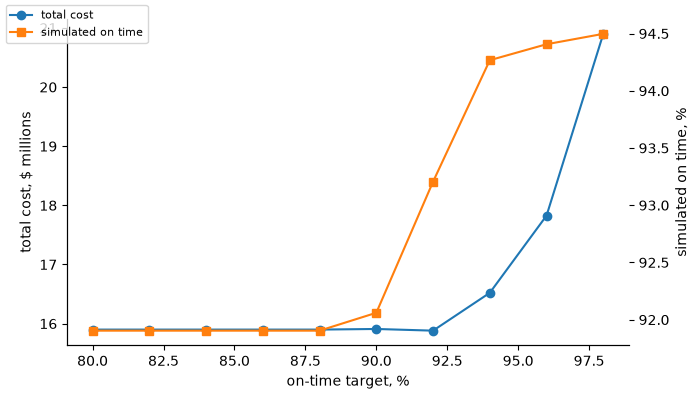

In [26]:
curve = sensitivity.cost_curve()
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curve["target"] * 100, curve["total_cost"] / 1e6, marker="o", label="total cost")
ax.set_xlabel("on-time target, %")
ax.set_ylabel("total cost, $ millions")
ax2 = ax.twinx()
ax2.plot(
    curve["target"] * 100,
    curve["on_time_pct"] * 100,
    marker="s",
    color="C1",
    label="simulated on time",
)
ax2.set_ylabel("simulated on time, %")
fig.legend(loc="upper left", fontsize=8)
fig.tight_layout()
curve.round(4)

### 7.2 2025 as it happened

From January to September 2025, requests came in below the forecast (section 3.3). Applying each department's ratio of actual to forecast requests to the whole year, the base plan held fixed against a plan re-solved for that demand:

In [27]:
print({c: round(r, 3) for c, r in sensitivity.actual_ratios().items()})
sensitivity.actuals_2025().set_index(["plan", "department"]).round(4)

{'PWDx': 0.844, 'BTDT': 0.928, 'PARK': 0.764, 'ISD': 0.954}


crew_cost  overdue_cost     total_cost  on_time_pct
plan       department                                                         
held fixed PWDx        7,810,833.340    71,452.024  7,882,285.364        0.967
           BTDT        2,859,999.980    77,180.494  2,937,180.474        0.952
           PARK        1,817,000.000       866.354  1,817,866.354        0.997
           ISD         3,021,666.700     2,285.328  3,023,952.028        0.994
           all        15,509,500.020   151,784.201 15,661,284.221        0.966
re-planned PWDx        6,803,333.333    81,961.364  6,885,294.698        0.962
           BTDT        2,621,666.667    86,934.776  2,708,601.443        0.946
           PARK        1,469,000.000       878.178  1,469,878.178        0.997
           ISD         2,916,666.667     2,293.928  2,918,960.594        0.994
           all        13,810,666.667   172,068.246 13,982,734.913        0.961

### What the sensitivity runs say

- **Demand 20% above forecast breaks a fixed plan.** With the base crews held, on-time falls to 14.8% and total cost reaches $27.21M, $11.70M of it in overdue penalties. Re-planned, it costs $20.52M at 90.6%, though Public Works (89.6%) and Transportation (89.8%) end just under 90%.
- **Demand 20% below forecast is safe either way.** Held fixed, the plan reaches 96.7% at $15.64M; re-planning releases crews and costs $13.05M at 96.5%.
- **A one-week snowstorm is the real risk for a fixed plan.** With the base crews, Public Works falls to 30.9% on time for the whole year, because it has almost no spare capacity and the February backlog never clears; the plan overall drops to 57.5%. Re-planned for the storm, it holds 91.4% for $17.88M, close to the $17.69M of holding the plan, but only by hiring a large Public Works crew for February and releasing it afterwards.
- **A heat wave barely matters:** 91.0% held fixed, 91.9% re-planned.
- **Higher targets cost a lot and buy little.** Targets from 80% to 88% give the same $15.90M plan at 91.9%, because covering each month's demand already gets close to 92%. A 92% target is reachable for $15.88M; the planner found that cheaper than its own 90% plan, a sign it is a heuristic. Above 92%, Public Works and Transportation can't reach the target: 98% costs $20.90M and still gives only 94.5%.
- **2025 as it happened would have needed fewer crews.** At 2025's actual demand, the base plan held fixed costs $15.66M at 96.6%; re-planned it costs $13.98M at 96.1%, with every department above 90%.

**Recommendation:** re-plan monthly as new demand comes in rather than fixing a 12-month plan, and give Public Works some winter slack or a storm-response plan, since that is where the plan is most fragile.

## 8. Equity and request sources

Both parts use 2024 and the same service-stats table as the app. On-time rates leave out requests with no target date.

### 8.1 Neighborhoods

For each department, neighborhoods with at least 200 requests in 2024, so a handful of requests can't decide a ranking.

In [28]:
MIN_REQUESTS = 200


def neighborhoods(code):
    f = {"department": code, "year": 2024}
    frames = [
        pd.DataFrame(query_service_stats(m, "neighborhood", f, limit=100)).set_index("neighborhood")
        for m in ("request_count", "on_time_rate", "median_days_to_close")
    ]
    out = pd.concat(frames, axis=1)
    return out[out["request_count"] >= MIN_REQUESTS].sort_values("on_time_rate")


hoods = {code: neighborhoods(code) for code in DEPARTMENTS}
spread = pd.DataFrame(
    {
        code: {
            "neighborhoods": len(h),
            "worst on-time": h.index[0],
            "worst rate": h["on_time_rate"].iloc[0],
            "best on-time": h.index[-1],
            "best rate": h["on_time_rate"].iloc[-1],
            "slowest": h["median_days_to_close"].idxmax(),
            "slowest median days": h["median_days_to_close"].max(),
            "fastest median days": h["median_days_to_close"].min(),
        }
        for code, h in hoods.items()
    }
).T
spread

,neighborhoods,worst on-time,worst rate,best on-time,best rate,slowest,slowest median days,fastest median days
PWDx,22,Charlestown,0.768,Beacon Hill,0.913,West Roxbury,0.600,0.100
BTDT,21,West Roxbury,0.354,South Boston / South Boston Waterfront,0.619,Hyde Park,4.300,0.400
PARK,20,Boston,0.892,Mission Hill,0.982,Hyde Park,12.400,1.000
ISD,20,Greater Mattapan,0.621,Allston / Brighton,0.777,Greater Mattapan,4.600,1.900


In [29]:
# the five neighborhoods with the lowest on-time rate in each department
pd.concat({code: h.head(5) for code, h in hoods.items()})

request_count  \
     neighborhood                                                  
PWDx Charlestown                                            3909   
     West Roxbury                                           5931   
     Brighton                                                827   
     Hyde Park                                              7571   
     Fenway / Kenmore / Audubon Circle / Longwood           1877   
BTDT West Roxbury                                           1678   
     Hyde Park                                              2027   
     Jamaica Plain                                          5566   
     Roslindale                                             2736   
     Charlestown                                            3541   
PARK Boston                                                 1296   
     Fenway / Kenmore / Audubon Circle / Longwood            337   
     Jamaica Plain                                          1177   
     Back Bay                                                428   
     Charlestown                                             686   
ISD  Greater Mattapan                                        967   
     East Boston                                            1153   
     Hyde Park                                               673   
     Downtown / Financial District                           813   
     Fenway / Kenmore / Audubon Circle / Longwood            416   

                                                   on_time_rate  \
     neighborhood                                                 
PWDx Charlestown                                          0.768   
     West Roxbury                                         0.804   
     Brighton                                             0.830   
     Hyde Park                                            0.835   
     Fenway / Kenmore / Audubon Circle / Longwood         0.836   
BTDT West Roxbury                                         0.354   
     Hyde Park                                            0.378   
     Jamaica Plain                                        0.381   
     Roslindale                                           0.414   
     Charlestown                                          0.420   
PARK Boston                                               0.892   
     Fenway / Kenmore / Audubon Circle / Longwood         0.898   
     Jamaica Plain                                        0.907   
     Back Bay                                             0.910   
     Charlestown                                          0.910   
ISD  Greater Mattapan                                     0.621   
     East Boston                                          0.644   
     Hyde Park                                            0.671   
     Downtown / Financial District                        0.696   
     Fenway / Kenmore / Audubon Circle / Longwood         0.701   

                                                   median_days_to_close  
     neighborhood                                                        
PWDx Charlestown                                                  0.500  
     West Roxbury                                                 0.600  
     Brighton                                                     0.200  
     Hyde Park                                                    0.600  
     Fenway / Kenmore / Audubon Circle / Longwood                 0.400  
BTDT West Roxbury                                                 4.200  
     Hyde Park                                                    4.300  
     Jamaica Plain                                                3.000  
     Roslindale                                                   3.000  
     Charlestown                                                  1.500  
PARK Boston                                                       1.000  
     Fenway / Kenmore / Audubon Circle / Longwood                 1.700  
     Jamaica Plain                         

### 8.2 Residents and city staff

Resident requests come from the app, phone calls and self service. Staff requests are Employee Generated or logged in the City Worker App.

In [30]:
s24 = stats[stats["year"] == 2024].copy()
s24["logged by"] = s24["source"].isin(RESIDENT_SOURCES).map({True: "resident", False: "staff"})
groups = s24.groupby(["department", "logged by"])
compare = pd.DataFrame(
    {
        "requests": groups.size(),
        "on-time rate": groups["on_time"].mean(),
        "median days to close": groups["close_days"].median(),
    }
)
compare.loc[list(DEPARTMENTS)].round(3)

requests  on-time rate  median days to close
department logged by                                              
PWDx       resident      79436         0.852                 0.529
           staff         78174         0.890                 0.121
BTDT       resident      31265         0.480                 1.635
           staff         50182         0.495                 0.883
PARK       resident       7429         0.902                 1.892
           staff         11307         0.948                 2.839
ISD        resident      11122         0.707                 3.242
           staff          7502         0.747                 2.223

In [31]:
# the most common request types for each group, as a share of that group's requests
mix = s24.groupby(["department", "logged by"])["request_type"].value_counts(normalize=True)
top = mix.groupby(["department", "logged by"], group_keys=False).head(3)
top.loc[list(DEPARTMENTS)].round(3).to_frame("share")

share
department logged by request_type                              
PWDx       resident  Requests for Street Cleaning         0.123
                     Improper Storage of Trash (Barrels)  0.111
                     Mattress_Pickup                      0.106
           staff     CE Collection                        0.230
                     Improper Storage of Trash (Barrels)  0.146
                     Requests for Street Cleaning         0.132
BTDT       resident  Parking Enforcement                  0.685
                     Sign Repair                          0.090
                     Abandoned Vehicles                   0.066
           staff     Parking Enforcement                  0.828
                     Abandoned Vehicles                   0.053
                     Sign Repair                          0.039
PARK       resident  Tree Maintenance Requests            0.318
                     Ground Maintenance                   0.223
                     Equipment Repair                     0.156
           staff     Tree Maintenance Requests            0.504
                     New Tree Requests                    0.150
                     Ground Maintenance                   0.125
ISD        resident  Rodent Activity                      0.226
                     Unsatisfactory Living Conditions     0.211
                     Pest Infestation - Residential       0.102
           staff     Rodent Activity                      0.288
                     Work w/out Permit                    0.100
                     Pest Infestation - Residential       0.093

peak / trough,resident,staff
department,,
PWDx,1.836,1.885
BTDT,1.354,1.452
PARK,4.655,3.277
ISD,1.646,2.317


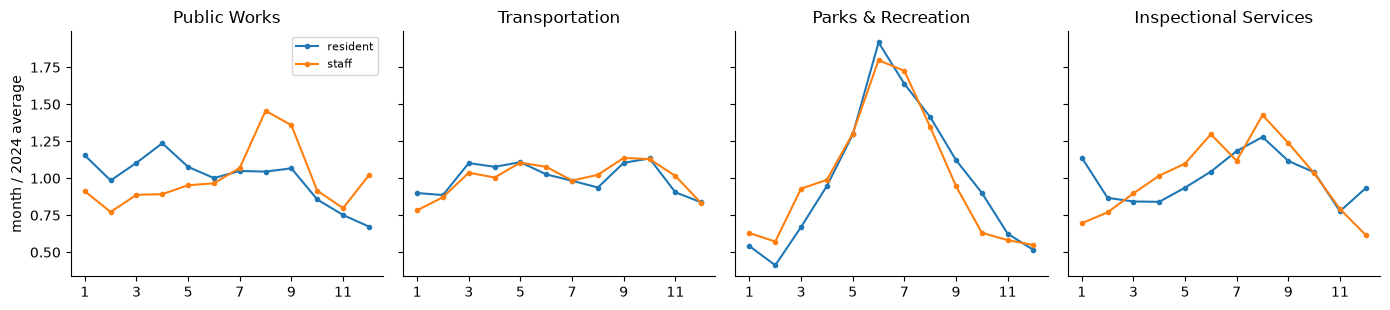

In [32]:
# monthly volume by group, each divided by its own 2024 monthly average
monthly_group = s24.groupby(["department", "logged by", "month"]).size()
shape = monthly_group / monthly_group.groupby(["department", "logged by"]).transform("mean")
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for ax, code in zip(axes, DEPARTMENTS, strict=True):
    for who in ("resident", "staff"):
        s = shape.loc[(code, who)]
        ax.plot(s.index.str[5:].astype(int), s.to_numpy(), marker=".", label=who)
    ax.set_title(NAMES[code])
    ax.set_xticks(range(1, 13, 2))
axes[0].legend(fontsize=8)
axes[0].set_ylabel("month / 2024 average")
fig.tight_layout()

peak = shape.groupby(["department", "logged by"]).agg(lambda s: s.max() / s.min())
peak.unstack().loc[list(DEPARTMENTS)].round(3).rename_axis(columns="peak / trough")

### 8.3 What this means

- **Transportation has the widest neighborhood gap.** In 2024 it closed 35% of West Roxbury requests on time, against 62% in South Boston and the Waterfront. Inspectional Services ranges from 62% (Greater Mattapan) to 78% (Allston / Brighton), and Public Works from 77% (Charlestown) to 91% (Beacon Hill). Parks is narrow, 89% to 98%; its lowest group is requests labelled only "Boston".
- **Close times vary most in Parks.** Hyde Park's median is 12.4 days, against 1.0 day in its fastest neighborhood.
- **Staff requests are on time more often in every department**: 89% against 85% in Public Works, 49% against 48% in Transportation, 95% against 90% in Parks, and 75% against 71% in Inspectional Services. They also close faster, except in Parks (2.8 days against 1.9).
- **Staff log different work.** 23% of Public Works staff requests are CE Collection, which doesn't appear among residents' top types, and 83% of Transportation staff requests are parking enforcement.
- **Residents drive Parks' summer peak.** Resident demand peaks at 4.7 times its low month, staff demand at 3.3 times. In Inspectional Services it's the other way round (2.3 for staff, 1.6 for residents).
- **To consider:** the plan counts staff-logged requests as workload like any other (working assumption 1). They are about half of it, and crews create much of that work themselves, so how it's scheduled matters as much as how many crews there are.